#  GAIA: микросервисная система с внедрёнными сбоями

GAIA выложила китайская компания CloudWise, которая делает инструменты для мониторинга. Название расшифровывается как Generic AIOps Atlas: атлас данных для умной эксплуатации систем....

Внутри две независимые части:

**MicroSS** - записи работы настоящей микросервисной системы, которую специально ломали 2 месяца

**Companion Data** - отдельный набор размеченных рядов для тренировки детекторов аномалий

| | |
|---|---|
| **Источник** | [CloudWise-OpenSource/GAIA-DataSet](https://github.com/CloudWise-OpenSource/GAIA-DataSet) |
| **Объём** | MicroSS — около 2 ГБ (метрики и трейсы разбиты на десятки архивов по 50 МБ); Companion Data — 19 МБ |

**Как устроена MicroSS** (сценарий «вход по QR-коду»):

Это учебная, но работающая система «вход на сайт по QR-коду»

Что происходит, когда пользователь входит:

1) Пользователь открывает сайт → webservice создаёт QR-код.
2) Код сохраняется в Redis через redisservice.
3) Пользователь сканирует код телефоном → mobservice записывает в Redis, кто это.
4) Сервис входа каждую секунду проверяет Redis: «отсканировали уже?»
5) Когда да → dbservice идёт в базу MySQL, находит аккаунт и выдаёт токен.


В ноутбуке беу Companion Data и журнал сбоев (`run.zip`, 0,8 МБ). Полные метрики MicroSS скачиваются отдельно (ячейка в конце будет скачиваться сто лет).

In [ ]:
# Общие настройки: библиотеки, стиль графиков, функция загрузки
import os, urllib.request, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 30)

C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']
ANOM = '#e34948'
plt.rcParams.update({
    'figure.figsize': (12, 3.6), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold', 'axes.titlesize': 11,
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'lines.linewidth': 1.2, 'axes.prop_cycle': plt.cycler(color=C), 'axes.axisbelow': True,
    'legend.frameon': False,
})
import matplotlib.dates as mdates

def fmt_dates(ax, fmt='%d.%m'):
    """Компактные подписи дат на оси X."""
    loc = mdates.AutoDateLocator(minticks=5, maxticks=10)
    ax.xaxis.set_major_locator(loc)
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))

def download(url, path, retries=3):
    """Скачивает файл, если его ещё нет; проверяет размер и повторяет при обрыве связи."""
    os.makedirs(os.path.dirname(path) or '.', exist_ok=True)
    if not os.path.exists(path):
        print('Скачиваю', url)
        for attempt in range(1, retries + 1):
            try:
                with urllib.request.urlopen(url, timeout=120) as r, open(path + '.part', 'wb') as f:
                    expected = int(r.headers.get('Content-Length') or 0)
                    while chunk := r.read(1 << 20):
                        f.write(chunk)
                if expected and os.path.getsize(path + '.part') != expected:
                    raise IOError('файл скачался не полностью')
                os.replace(path + '.part', path)
                break
            except Exception as e:
                print(f'  попытка {attempt} не удалась: {e}')
                if attempt == retries: raise
    print(f'{path}: {os.path.getsize(path)/1e6:.1f} МБ')

## 1. Загрузка

In [ ]:
import zipfile, glob, re
DATA = 'data/gaia'
BASE = 'https://raw.githubusercontent.com/CloudWise-OpenSource/GAIA-DataSet/main/'
for f in ['Companion_Data/metric_detection.zip', 'Companion_Data/metric_forecast.zip', 'MicroSS/run/run.zip']:
    path = f'{DATA}/{os.path.basename(f)}'
    download(BASE + f, path)
    zipfile.ZipFile(path).extractall(DATA)

Скачиваю https://raw.githubusercontent.com/CloudWise-OpenSource/GAIA-DataSet/main/Companion_Data/metric_detection.zip
data/gaia/metric_detection.zip: 12.8 МБ
Скачиваю https://raw.githubusercontent.com/CloudWise-OpenSource/GAIA-DataSet/main/Companion_Data/metric_forecast.zip
data/gaia/metric_forecast.zip: 6.2 МБ
Скачиваю https://raw.githubusercontent.com/CloudWise-OpenSource/GAIA-DataSet/main/MicroSS/run/run.zip
data/gaia/run.zip: 0.8 МБ


## 2. Companion Data: размеченные ряды для детекции аномалий

Набор из 279 отдельных рядов, не связанных с MicroSS. Каждый файл — простая таблица из трёх столбцов:

- timestamp — время в миллисекундах (шаг 5 минут);
- value — значение метрики;
- label — 1, если точка аномальная, 0, если нормальная.

In [ ]:
rows = []
for f in glob.glob(f'{DATA}/metric_detection/*/*.csv'):
    d = pd.read_csv(f)
    rows.append({'тип': os.path.basename(os.path.dirname(f)), 'файл': os.path.basename(f), 'точек': len(d),
                 'шаг, мин': d.timestamp.diff().median() / 60000, 'дней': (d.timestamp.max() - d.timestamp.min()) / 86400000,
                 'аномалий, %': d.label.mean() * 100, 'пропусков': int(d.value.isna().sum())})
det = pd.DataFrame(rows)
print('Рядов:', len(det), '| пропусков в значениях:', det['пропусков'].sum())
display(det.groupby('тип').agg(рядов=('файл', 'size'), точек_медиана=('точек', 'median'),
        шаг_мин=('шаг, мин', 'median'), дней_медиана=('дней', 'median'),
        аномалий_проц=('аномалий, %', 'mean')).round(2).sort_values('рядов', ascending=False))

Рядов: 279 | пропусков в значениях: 0


,рядов,точек_медиана,шаг_мин,дней_медиана,аномалий_проц
тип,,,,,
partially_stationary_data,71,8640.0,5.0,30.00,0.30
linear_data,59,12672.0,5.0,44.00,0.08
low_signal-to-noise_ratio_data,50,8640.0,5.0,30.00,2.76
periodic_data,43,8001.0,5.0,27.77,1.12
changepoint_data,35,12672.0,5.0,44.00,0.66
staircase_data,18,12672.0,5.0,44.00,0.40
concept_drift_data,3,12672.0,5.0,44.00,0.15


Ряды разложены по типу поведения:
- partially stationary: в основном ровный, иногда меняется
- linear: растёт или падает по прямой и т.д (смотрите подписи на графиках)

Большой график показывает по примеру каждого типа, красные точки это опять же аномалии.

Странно что на некоторых рядах аномалия — это прямая линия. Похоже, там пропали данные или я че то неправильно понимаю

Удобно проверять, как детектор справляется с рядами разной формы: на ровном ряду аномалию найти легко, на шумном трудно


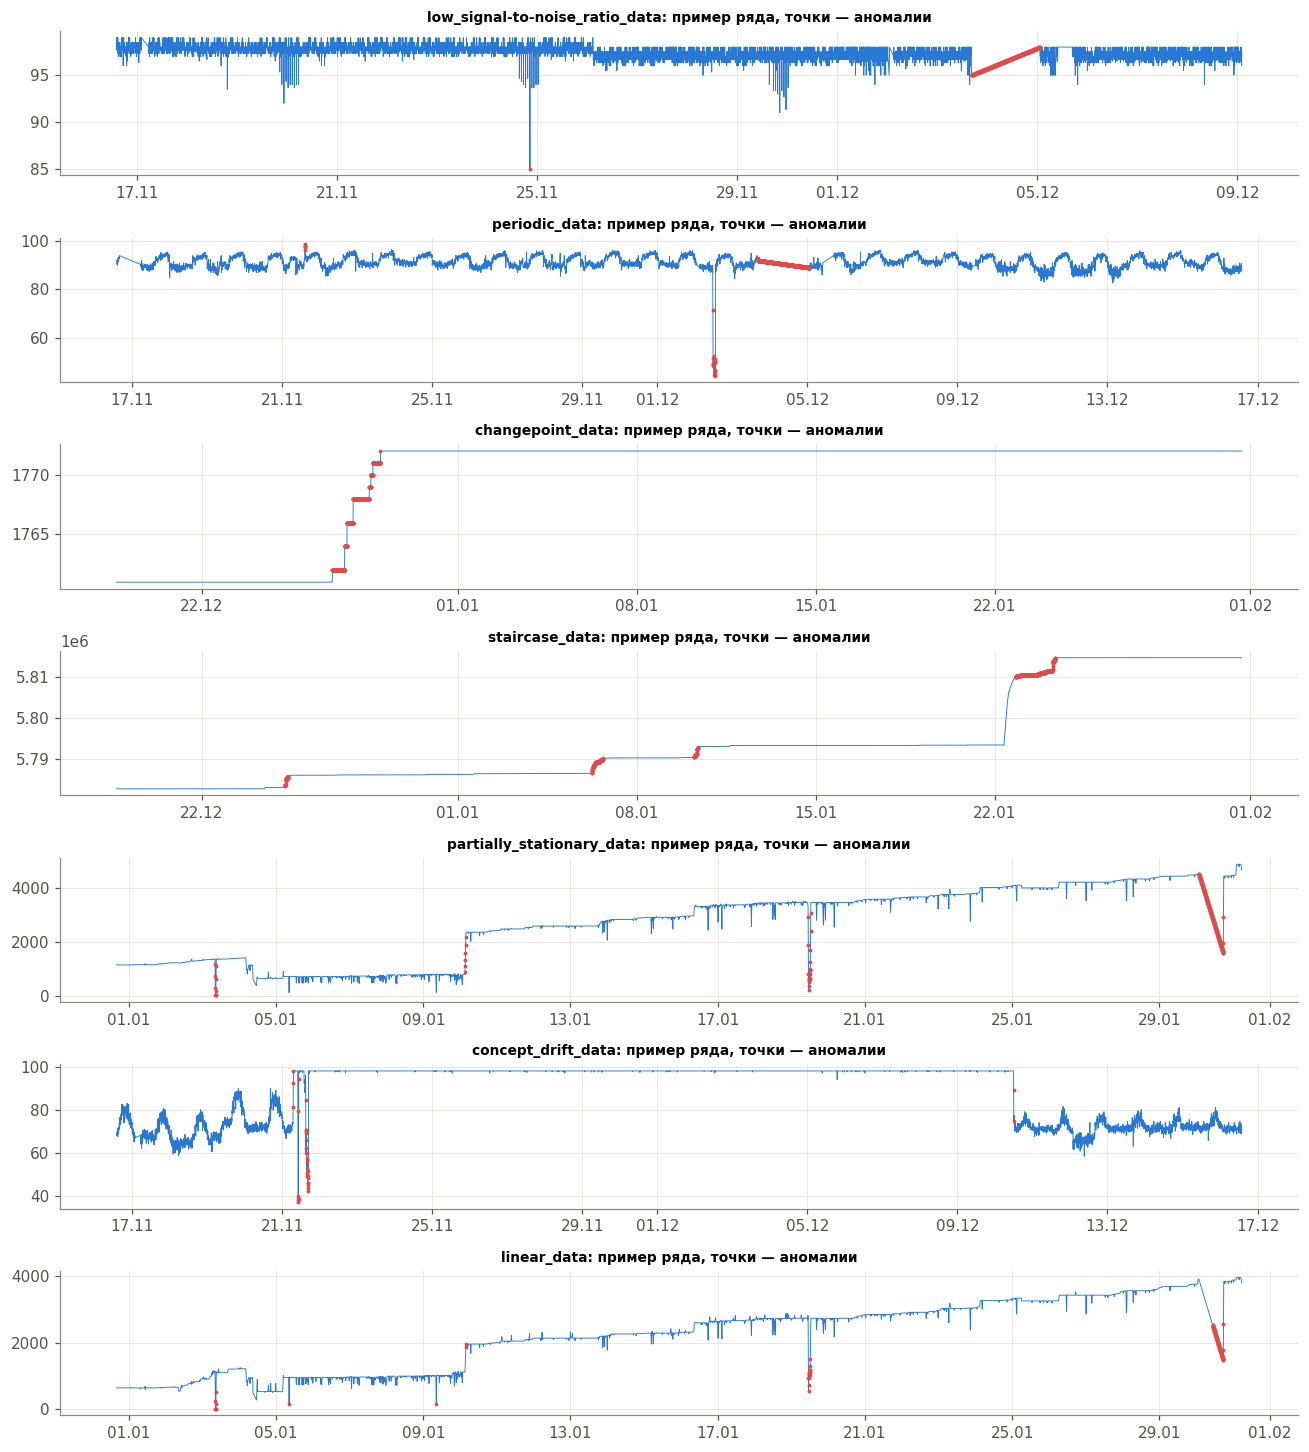

In [ ]:
types = det.groupby('тип')['аномалий, %'].mean().sort_values(ascending=False).index.tolist()
fig, axes = plt.subplots(len(types), 1, figsize=(12, 1.9 * len(types)))
for ax, t in zip(axes, types):
    f = det[(det['тип'] == t) & (det['аномалий, %'] > 0)].sort_values('аномалий, %').iloc[-1]['файл'] if (det[det['тип'] == t]['аномалий, %'] > 0).any() else det[det['тип'] == t].iloc[0]['файл']
    d = pd.read_csv(f'{DATA}/metric_detection/{t}/{f}')
    d['time'] = pd.to_datetime(d.timestamp, unit='ms')
    ax.plot(d.time, d.value, lw=0.6, color=C[0])
    a = d[d.label == 1]
    ax.plot(a.time, a.value, lw=0, marker='.', ms=3, color=ANOM)
    ax.set_title(f'{t}: пример ряда, точки — аномалии', fontsize=9); fmt_dates(ax)
plt.tight_layout(); plt.show()

## 3. MicroSS: журнал внедрённых сбоев

Это обычная таблица из 36 574 строк и трёх столбцов:

- datetime — день;
- service — в каком сервисе это произошло;
- message — текст записи: здесь написано, что именно сделали.

Дальше жесть какая то:

Шаг 1. Склеиваем два файла:

Журнал разбит на два файла, за июль и за август. Объединяем их в одну таблицу.

Шаг 2. Достаём время и текст:

Из message вырезаем:

- время (первые 19 символов: 2021-07-01 11:54:27);
- смысловую часть (всё после последней черты |).

Шаг 3. Определяем тип сбоя по ключевым словам

Ищем в тексте характерные фразы:

Шаг 4. Считаем, сколько каких сбоев в каком сервисе

Получается таблица «тип сбоя × сервис»:

- нехватка памяти — 1 367 раз, во всех сервисах примерно поровну;
- CPU — 81 раз, в основном dbservice и mobservice;
- диск — 79 раз, только webservice;
- отказ в доступе — 35 раз, только dbservice;
- ошибки MySQL — 38 раз.

Шаг 5. Рисуем расписание сбоев

График, где:

по вертикали 10 сервисов;
по горизонтали время, июль–август;
каждая точка — один сбой, цвет — его тип.

Из графика видно, что сбои равномерно разбросаны по всем сервисам и по всему времени

Шаг 6. Длительность

Из текста вытаскиваем «lasts 600 seconds»: все сбои длятся ровно 10 минут. В среднем ~27 сбоев в сутки

In [ ]:
run = pd.concat([pd.read_csv(f) for f in sorted(glob.glob(f'{DATA}/run/*.csv'))], ignore_index=True)
print(run.shape, '| сервисов:', run.service.nunique(), sorted(run.service.unique()))
run['text'] = run.message.fillna('').str.split('|').str[-1].str.strip()
run['time'] = pd.to_datetime(run.message.str.slice(0, 19), errors='coerce')

PATTERNS = {'память (memory)': r'\[memory_anomalies\]', 'CPU': r'\[cpu_anomalies\]',
            'перемещение файлов (диск)': r'file moving program', 'отказ в доступе': r'access permission denied',
            'сбой входа по QR-коду': r'login failure of the QR code', 'ошибка подключения к MySQL': r"Can't connect to MySQL"}
run['сбой'] = None
for name, pat in PATTERNS.items():
    run.loc[run.text.str.contains(pat, regex=True, na=False), 'сбой'] = name
inj = run.dropna(subset=['сбой']).copy()
inj['тип сервиса'] = inj.service.str.replace(r'\d$', '', regex=True)
print('Записей о сбоях:', len(inj))
display(pd.crosstab(inj['сбой'], inj['тип сервиса'], margins=True, margins_name='всего'))

(36574, 4) | сервисов: 10 ['dbservice1', 'dbservice2', 'logservice1', 'logservice2', 'mobservice1', 'mobservice2', 'redisservice1', 'redisservice2', 'webservice1', 'webservice2']


Записей о сбоях: 34293


тип сервиса,dbservice,logservice,mobservice,redisservice,webservice,всего
сбой,,,,,,
CPU,39,2,35,2,3,81
отказ в доступе,35,0,0,0,0,35
ошибка подключения к MySQL,7,8,7,8,8,38
память (memory),309,271,266,250,271,1367
перемещение файлов (диск),0,0,0,0,79,79
сбой входа по QR-коду,0,0,32693,0,0,32693
всего,390,281,33001,260,361,34293


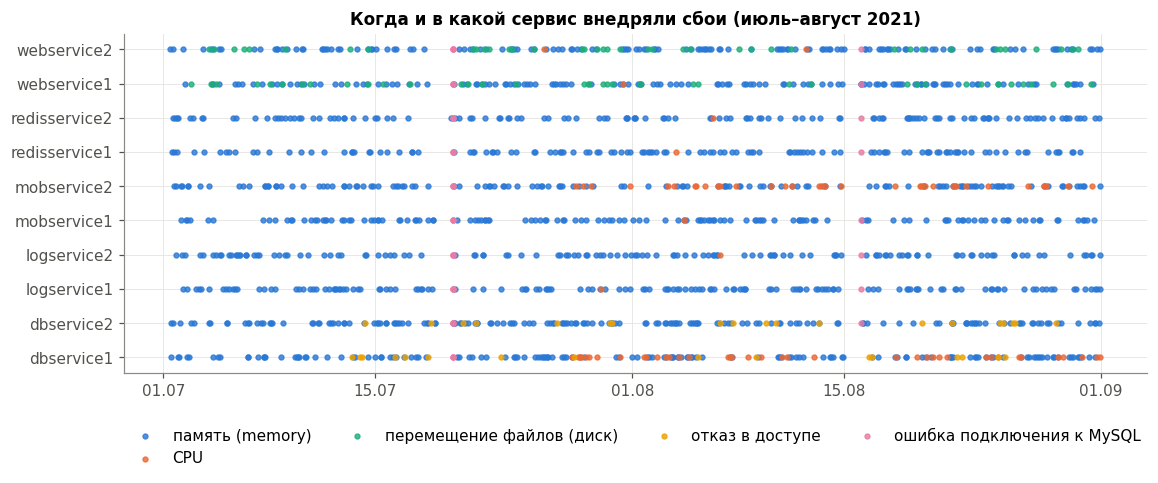

Длительность сбоя, с (по тексту записи):
count    1446.0
mean      600.0
std         0.0
min       600.0
25%       600.0
50%       600.0
75%       600.0
max       600.0

Сбоев в сутки, медиана: 27.0


In [ ]:
faults = inj[~inj['сбой'].isin(['сбой входа по QR-коду'])]          # «настоящие» внедрённые сбои ресурсов
services = sorted(faults.service.unique())
kinds = [k for k in PATTERNS if k in faults['сбой'].unique()]
fig, ax = plt.subplots(figsize=(12, 4))
for i, k in enumerate(kinds):
    sub = faults[faults['сбой'] == k]
    ax.scatter(sub.time, [services.index(s) for s in sub.service], s=10, color=C[i], label=k, alpha=0.8)
ax.set_yticks(range(len(services))); ax.set_yticklabels(services)
ax.set_title('Когда и в какой сервис внедряли сбои (июль–август 2021)'); ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12))
fmt_dates(ax); plt.show()
dur = faults.text.str.extract(r'lasts? (?:for )?(\d+) seconds')[0].astype(float)
print('Длительность сбоя, с (по тексту записи):'); print(dur.describe().round(0).to_string())
print('\nСбоев в сутки, медиана:', faults.groupby(faults.time.dt.date).size().median())

## 4. Полные метрики MicroSS

Метрики сервисов разбиты на 35 частей по ~50 МБ (`metric_split.z01 … .z34` + `.zip`), всего ~1,8 ГБ. В Colab это скачивается не очень быстро. Если тут  `True`, то можно скачать.

In [ ]:
DOWNLOAD_FULL_METRICS = False
if DOWNLOAD_FULL_METRICS:
    for i in range(1, 35):
        download(f'{BASE}MicroSS/metric/metric_split.z{i:02d}', f'{DATA}/metric/metric_split.z{i:02d}')
    download(f'{BASE}MicroSS/metric/metric_split.zip', f'{DATA}/metric/metric_split.zip')
    os.system(f'cd {DATA}/metric && zip -s 0 metric_split.zip --out metric_full.zip && unzip -q -o metric_full.zip')
    # имя файла метрики: <сервис>_<ip>_<метрика>_<период>.csv, поля timestamp, value

## 5. Выводы

**Что увидели**
- **Companion Data:** 279 размеченных рядов с шагом 5 минут, по 1–1,5 месяца, без пропусков в значениях. Ряды разложены по типу поведения: стационарные, линейные, периодические, со ступеньками, со сменой уровня, с дрейфом. Аномалий мало: 0,1–2,8% точек в зависимости от типа.
- **Разметка Companion местами спорная:** часть «аномалий» — участки, где данные, похоже, пропали и заполнены прямой линией. При обучении это нужно учитывать.
- **Журнал сбоев MicroSS:**
  - за 2 месяца ~1,6 тыс. внедрённых сбоев ресурсов, ~27 в сутки, каждый длится ровно 10 минут;
  - типы: нехватка памяти (1367, во всех сервисах примерно поровну), CPU (81, в основном dbservice и mobservice), «перемещение файлов» / диск (79, только webservice), отказ в доступе (35, только dbservice), ошибки подключения к MySQL;
  - отдельно ~33 тыс. записей «сбой входа по QR-коду» в mobservice: это имитация поведения пользователей, а не сбой ресурсов.

**Минусы**
- Тоже объемно
- Сбои искусственные и однообразные, нет перегрузки по входящему трафику
- Там в доке все по китайски, тяжеловато через переводчик разбираться в сути

